# AQI Forecasting Project
## 02 — Data Cleaning

### Objective
Create a reliable cleaned dataset from the original raw data.

### Principles
1. Never modify the original raw dataset.
2. Preserve valid pollution observations.
3. Avoid artificial interpolation across long gaps.
4. Document every cleaning decision.
5. Validate the cleaned dataset before feature engineering.

In [1]:
# Imports and configuration

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)

PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

RAW_FILE = PROJECT_DIR.parent / "hourly_air_quality_raw.csv"

DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)

print("Raw file exists:", RAW_FILE.exists())
print("Data directory:", DATA_DIR)

Raw file exists: True
Data directory: C:\Users\anshu\Desktop\ML project\aqi-intelligence\aqi-intelligence\datanew\aqi_rebuild\data


In [2]:
# Load a fresh copy of the original dataset

raw_df = pd.read_csv(RAW_FILE, low_memory=False)

# Create a separate working copy
clean_df = raw_df.copy()

print("Raw shape:", raw_df.shape)
print("Working shape:", clean_df.shape)

print("Original dataset remains separate:", raw_df is not clean_df)

Raw shape: (190514, 19)
Working shape: (190514, 19)
Original dataset remains separate: True


In [3]:
# Standardize timestamp representation

clean_df["observed_at"] = pd.to_datetime(
    clean_df["observed_at"],
    utc=True,
    errors="coerce"
)

clean_df["observed_at_ist"] = (
    clean_df["observed_at"].dt.tz_convert("Asia/Kolkata")
)

print("Invalid timestamps:", clean_df["observed_at"].isna().sum())

display(
    clean_df[
        ["observed_at", "observed_at_ist", "station_name"]
    ].head()
)

Invalid timestamps: 0


,observed_at,observed_at_ist,station_name
0,2025-02-18 19:30:00+00:00,2025-02-19 01:00:00+05:30,"ITO, New Delhi - CPCB"
1,2025-02-18 20:30:00+00:00,2025-02-19 02:00:00+05:30,"ITO, New Delhi - CPCB"
2,2025-02-18 21:30:00+00:00,2025-02-19 03:00:00+05:30,"ITO, New Delhi - CPCB"
3,2025-02-18 22:30:00+00:00,2025-02-19 04:00:00+05:30,"ITO, New Delhi - CPCB"
4,2025-02-18 23:30:00+00:00,2025-02-19 05:00:00+05:30,"ITO, New Delhi - CPCB"


## 2. Missing Value Assessment

Before applying any cleaning operations, we will:
1. Calculate missing values by variable.
2. Calculate missing values by station.
3. Identify variables with severe missingness.
4. Establish a strategy for each variable.

No imputation or row deletion will be performed yet.

In [4]:
# Overall missing value summary

missing_summary = pd.DataFrame({
    "Missing_Count": clean_df.isna().sum(),
    "Missing_Percentage": (
        clean_df.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
wind_direction,35319,18.54
so2,28694,15.06
wind_speed,27824,14.60
no2,26512,13.92
relative_humidity,26164,13.73
temperature,26117,13.71
o3,17892,9.39
pm25,14039,7.37
no,13186,6.92
nox,12536,6.58


In [5]:
# Missing values by station

measurement_columns = [
    "co", "no", "no2", "nox", "o3",
    "pm10", "pm25", "relative_humidity",
    "so2", "temperature", "wind_direction",
    "wind_speed"
]

station_missing = (
    clean_df.groupby("station_name")[measurement_columns]
    .apply(lambda x: x.isna().mean() * 100)
    .round(2)
)

display(station_missing)

,co,no,no2,nox,o3,pm10,pm25,relative_humidity,so2,temperature,wind_direction,wind_speed
station_name,,,,,,,,,,,,
"Alipur, Delhi - DPCC",1.75,0.73,0.85,0.58,1.74,1.64,1.35,3.96,1.46,3.21,3.22,14.23
"Anand Vihar, New Delhi - DPCC",1.97,2.67,100.00,1.09,85.44,3.08,1.77,0.53,100.00,0.50,0.64,0.55
"Aya Nagar, New Delhi - IMD",100.00,100.00,100.00,100.00,100.00,0.00,100.00,100.00,100.00,100.00,100.00,100.00
"Bawana, Delhi - DPCC",2.40,2.47,1.78,1.71,0.58,1.38,1.96,0.27,2.04,0.27,1.27,2.77
"Dwarka-Sector 8, Delhi - DPCC",1.31,0.76,0.70,0.70,1.03,0.85,1.21,0.03,1.47,0.03,0.06,0.08
"ITO, New Delhi - CPCB",0.05,0.02,0.03,0.02,0.27,2.97,2.14,100.00,1.19,100.00,100.00,100.00
"Lodhi Road, New Delhi - IMD",37.57,100.00,100.00,100.00,0.45,100.00,100.00,100.00,100.00,100.00,100.00,100.00
"Mandir Marg, New Delhi - DPCC",2.19,2.11,2.59,1.47,2.07,1.71,4.74,0.01,6.67,0.00,3.38,0.01
"Mundka, Delhi - DPCC",1.12,0.66,0.24,0.32,3.43,1.16,1.26,0.59,2.21,1.10,1.14,0.57


## 3. Consecutive Missing PM2.5 Analysis

We will identify consecutive missing PM2.5 periods for every station.

The hourly timeline will be reconstructed between each station's
first and last observation.

This will capture both:
- Existing records where PM2.5 is null.
- Entire missing timestamps where no observation was recorded.

We will use these results to decide whether short-gap imputation
is appropriate.

In [6]:
# Reconstruct hourly timelines and inspect PM2.5 missing runs

pm25_gap_results = []

for station, group in clean_df.groupby("station_name"):

    station_data = (
        group.set_index("observed_at_ist")
        .sort_index()
    )

    full_index = pd.date_range(
        start=station_data.index.min(),
        end=station_data.index.max(),
        freq="h"
    )

    hourly_data = station_data.reindex(full_index)

    missing = hourly_data["pm25"].isna()

    run_ids = missing.ne(missing.shift()).cumsum()

    missing_runs = (
        missing[missing]
        .groupby(run_ids[missing])
        .size()
    )

    pm25_gap_results.append({
        "Station": station,
        "Total_Hours": len(hourly_data),
        "Missing_PM25_Hours": int(missing.sum()),
        "Missing_Percentage": round(
            missing.mean() * 100, 2
        ),
        "Missing_Runs": len(missing_runs),
        "Longest_Missing_Run_Hours": (
            int(missing_runs.max())
            if len(missing_runs) else 0
        )
    })

pm25_gap_summary = pd.DataFrame(pm25_gap_results)

display(
    pm25_gap_summary.sort_values(
        "Longest_Missing_Run_Hours",
        ascending=False
    )
)

,Station,Total_Hours,Missing_PM25_Hours,Missing_Percentage,Missing_Runs,Longest_Missing_Run_Hours
6,"Lodhi Road, New Delhi - IMD",10551,10551,100.00,1,10551
2,"Aya Nagar, New Delhi - IMD",4072,4072,100.00,1,4072
0,"Alipur, Delhi - DPCC",15202,1879,12.36,345,242
1,"Anand Vihar, New Delhi - DPCC",15206,1713,11.27,377,242
3,"Bawana, Delhi - DPCC",15206,1585,10.42,314,242
4,"Dwarka-Sector 8, Delhi - DPCC",15209,1459,9.59,280,242
5,"ITO, New Delhi - CPCB",15209,1583,10.41,243,242
7,"Mandir Marg, New Delhi - DPCC",15209,2096,13.78,485,242
8,"Mundka, Delhi - DPCC",15209,1465,9.63,289,242
9,"Patparganj, Delhi - DPCC",15208,1538,10.11,267,242


## 4. PM2.5 Missing Gap Length Distribution

We will classify consecutive missing PM2.5 periods by duration.

This helps distinguish short gaps, which may be candidates for
limited interpolation, from long outages that must remain missing.

In [7]:
# Classify consecutive PM2.5 missing runs by duration

gap_length_results = []

for station, group in clean_df.groupby("station_name"):

    station_data = (
        group.set_index("observed_at_ist")
        .sort_index()
    )

    full_index = pd.date_range(
        start=station_data.index.min(),
        end=station_data.index.max(),
        freq="h"
    )

    hourly_data = station_data.reindex(full_index)

    missing = hourly_data["pm25"].isna()
    run_ids = missing.ne(missing.shift()).cumsum()

    missing_runs = (
        missing[missing]
        .groupby(run_ids[missing])
        .size()
    )

    gap_length_results.append({
        "Station": station,
        "1-2 Hours": int(((missing_runs >= 1) & (missing_runs <= 2)).sum()),
        "3-6 Hours": int(((missing_runs >= 3) & (missing_runs <= 6)).sum()),
        "7-12 Hours": int(((missing_runs >= 7) & (missing_runs <= 12)).sum()),
        "13-24 Hours": int(((missing_runs >= 13) & (missing_runs <= 24)).sum()),
        "25-48 Hours": int(((missing_runs >= 25) & (missing_runs <= 48)).sum()),
        "Above 48 Hours": int((missing_runs > 48).sum()),
        "Total Missing Runs": len(missing_runs)
    })

gap_length_summary = pd.DataFrame(gap_length_results)

display(gap_length_summary)

,Station,1-2 Hours,3-6 Hours,7-12 Hours,13-24 Hours,25-48 Hours,Above 48 Hours,Total Missing Runs
0,"Alipur, Delhi - DPCC",218,71,21,24,6,5,345
1,"Anand Vihar, New Delhi - DPCC",261,62,24,22,4,4,377
2,"Aya Nagar, New Delhi - IMD",0,0,0,0,0,1,1
3,"Bawana, Delhi - DPCC",208,63,18,16,2,7,314
4,"Dwarka-Sector 8, Delhi - DPCC",192,44,20,17,2,5,280
5,"ITO, New Delhi - CPCB",167,34,16,17,3,6,243
6,"Lodhi Road, New Delhi - IMD",0,0,0,0,0,1,1
7,"Mandir Marg, New Delhi - DPCC",324,91,37,24,5,4,485
8,"Mundka, Delhi - DPCC",188,55,21,19,2,4,289
9,"Patparganj, Delhi - DPCC",169,48,21,19,6,4,267


In [8]:
# Examine missing PM2.5 runs of 1–6 hours

short_gap_details = []

for station, group in clean_df.groupby("station_name"):

    station_data = (
        group.set_index("observed_at_ist")
        .sort_index()
    )

    full_index = pd.date_range(
        start=station_data.index.min(),
        end=station_data.index.max(),
        freq="h"
    )

    hourly_data = station_data.reindex(full_index)

    missing = hourly_data["pm25"].isna()
    run_ids = missing.ne(missing.shift()).cumsum()

    for run_id, run in missing[missing].groupby(run_ids[missing]):

        duration = len(run)

        if 1 <= duration <= 6:
            start_time = run.index.min()
            end_time = run.index.max()

            short_gap_details.append({
                "Station": station,
                "Gap_Start": start_time,
                "Gap_End": end_time,
                "Missing_Hours": duration,
                "PM25_Before": hourly_data["pm25"].asof(
                    start_time - pd.Timedelta(hours=1)
                ),
                "PM25_After": hourly_data["pm25"].asof(
                    end_time + pd.Timedelta(hours=1)
                )
            })

short_gap_df = pd.DataFrame(short_gap_details)

print("Total short gaps:", len(short_gap_df))
display(short_gap_df.head(30))

Total short gaps: 3426


,Station,Gap_Start,Gap_End,Missing_Hours,PM25_Before,PM25_After
0,"Alipur, Delhi - DPCC",2025-04-05 13:00:00+05:30,2025-04-05 14:00:00+05:30,2,22.80,18.0
1,"Alipur, Delhi - DPCC",2025-04-11 22:00:00+05:30,2025-04-12 01:00:00+05:30,4,14.80,11.0
2,"Alipur, Delhi - DPCC",2025-04-16 21:00:00+05:30,2025-04-16 22:00:00+05:30,2,88.00,124.0
3,"Alipur, Delhi - DPCC",2025-04-18 17:00:00+05:30,2025-04-18 18:00:00+05:30,2,66.00,70.0
4,"Alipur, Delhi - DPCC",2025-04-28 00:00:00+05:30,2025-04-28 00:00:00+05:30,1,128.00,102.0
5,"Alipur, Delhi - DPCC",2025-04-29 20:00:00+05:30,2025-04-29 21:00:00+05:30,2,68.50,82.0
6,"Alipur, Delhi - DPCC",2025-05-02 07:00:00+05:30,2025-05-02 11:00:00+05:30,5,40.00,40.0
7,"Alipur, Delhi - DPCC",2025-05-20 20:00:00+05:30,2025-05-20 20:00:00+05:30,1,78.80,95.5
8,"Alipur, Delhi - DPCC",2025-05-26 17:00:00+05:30,2025-05-26 17:00:00+05:30,1,63.00,52.0
9,"Alipur, Delhi - DPCC",2025-05-27 12:00:00+05:30,2025-05-27 12:00:00+05:30,1,45.80,53.0


In [9]:
# Verify the immediately adjacent PM2.5 readings

verified_gaps = []

for _, gap in short_gap_df.iterrows():

    station_data = (
        clean_df[clean_df["station_name"] == gap["Station"]]
        .set_index("observed_at_ist")
        .sort_index()
    )

    before_time = gap["Gap_Start"] - pd.Timedelta(hours=1)
    after_time = gap["Gap_End"] + pd.Timedelta(hours=1)

    before = station_data["pm25"].get(before_time, np.nan)
    after = station_data["pm25"].get(after_time, np.nan)

    verified_gaps.append({
        "Station": gap["Station"],
        "Gap_Start": gap["Gap_Start"],
        "Missing_Hours": gap["Missing_Hours"],
        "Immediate_Before": before,
        "Immediate_After": after,
        "Both_Neighbours_Available": (
            pd.notna(before) and pd.notna(after)
        )
    })

verified_gap_df = pd.DataFrame(verified_gaps)

print("Total short gaps:", len(verified_gap_df))

print(
    "Gaps with both immediate neighbours:",
    verified_gap_df["Both_Neighbours_Available"].sum()
)

print(
    "Gaps without both immediate neighbours:",
    (~verified_gap_df["Both_Neighbours_Available"]).sum()
)

display(verified_gap_df.head(30))

Total short gaps: 3426
Gaps with both immediate neighbours: 3426
Gaps without both immediate neighbours: 0


,Station,Gap_Start,Missing_Hours,Immediate_Before,Immediate_After,Both_Neighbours_Available
0,"Alipur, Delhi - DPCC",2025-04-05 13:00:00+05:30,2,22.80,18.0,True
1,"Alipur, Delhi - DPCC",2025-04-11 22:00:00+05:30,4,14.80,11.0,True
2,"Alipur, Delhi - DPCC",2025-04-16 21:00:00+05:30,2,88.00,124.0,True
3,"Alipur, Delhi - DPCC",2025-04-18 17:00:00+05:30,2,66.00,70.0,True
4,"Alipur, Delhi - DPCC",2025-04-28 00:00:00+05:30,1,128.00,102.0,True
5,"Alipur, Delhi - DPCC",2025-04-29 20:00:00+05:30,2,68.50,82.0,True
6,"Alipur, Delhi - DPCC",2025-05-02 07:00:00+05:30,5,40.00,40.0,True
7,"Alipur, Delhi - DPCC",2025-05-20 20:00:00+05:30,1,78.80,95.5,True
8,"Alipur, Delhi - DPCC",2025-05-26 17:00:00+05:30,1,63.00,52.0,True
9,"Alipur, Delhi - DPCC",2025-05-27 12:00:00+05:30,1,45.80,53.0,True


## Interpolation Validation — Simulated Missing Blocks

Before filling actual missing PM2.5 values, we will evaluate
linear interpolation on artificially hidden observations.

We will:
1. Select continuous blocks of 1–6 observed hours.
2. Temporarily hide their PM2.5 readings.
3. Estimate the hidden readings using linear interpolation.
4. Compare estimates against the original readings.
5. Calculate MAE and RMSE for each gap length.

This helps determine which gap lengths can be interpolated reliably.

In [13]:
# Validate linear interpolation using simulated missing blocks

from sklearn.metrics import mean_absolute_error, mean_squared_error

rng = np.random.default_rng(42)

validation_results = []

for station, group in clean_df.groupby("station_name"):

    station_data = (
        group.set_index("observed_at_ist")["pm25"]
        .sort_index()
    )

    full_index = pd.date_range(
        start=station_data.index.min(),
        end=station_data.index.max(),
        freq="h"
    )

    series = station_data.reindex(full_index)

    # Exclude stations with no PM2.5 observations
    if series.notna().sum() == 0:
        continue

    for gap_length in range(1, 7):

        # Find windows where every value, including both
        # boundary readings, is originally available
        candidates = []

        for start in range(len(series) - gap_length - 1):

            window = series.iloc[
                start : start + gap_length + 2
            ]

            if window.notna().all():
                candidates.append(start)

        if not candidates:
            continue

        # Randomly sample up to 100 windows
        sample_size = min(100, len(candidates))

        selected = rng.choice(
            candidates,
            size=sample_size,
            replace=False
        )

        actual_values = []
        predicted_values = []

        for start in selected:

            window = series.iloc[
                start : start + gap_length + 2
            ].to_numpy()

            # Boundary readings
            left_value = window[0]
            right_value = window[-1]

            # Linear interpolation between boundaries
            estimates = np.linspace(
                left_value,
                right_value,
                gap_length + 2
            )[1:-1]

            actual = window[1:-1]

            actual_values.extend(actual)
            predicted_values.extend(estimates)

        mae = mean_absolute_error(
            actual_values,
            predicted_values
        )

        rmse = np.sqrt(
            mean_squared_error(
                actual_values,
                predicted_values
            )
        )

        validation_results.append({
            "Station": station,
            "Gap_Length_Hours": gap_length,
            "Test_Blocks": sample_size,
            "Test_Readings": len(actual_values),
            "MAE": mae,
            "RMSE": rmse
        })

interpolation_validation = pd.DataFrame(validation_results)

display(
    interpolation_validation
    .groupby("Gap_Length_Hours")
    .agg({
        "Test_Blocks": "sum",
        "Test_Readings": "sum",
        "MAE": "mean",
        "RMSE": "mean"
    })
    .round(2)
)

print("\nStation-wise validation:")
display(interpolation_validation.round(2))

,Test_Blocks,Test_Readings,MAE,RMSE
Gap_Length_Hours,,,,
1,1300,1300,7.98,12.54
2,1300,2600,10.62,16.84
3,1300,3900,12.92,20.71
4,1300,5200,14.77,24.40
5,1300,6500,16.50,25.81
6,1300,7800,18.92,30.33



Station-wise validation:


,Station,Gap_Length_Hours,Test_Blocks,Test_Readings,MAE,RMSE
0,"Alipur, Delhi - DPCC",1,100,100,8.11,12.73
1,"Alipur, Delhi - DPCC",2,100,200,10.44,16.34
2,"Alipur, Delhi - DPCC",3,100,300,10.83,18.22
3,"Alipur, Delhi - DPCC",4,100,400,12.42,19.53
4,"Alipur, Delhi - DPCC",5,100,500,15.71,25.45
...,...,...,...,...,...,...
73,"Vivek Vihar, Delhi - DPCC",2,100,200,9.69,17.22
74,"Vivek Vihar, Delhi - DPCC",3,100,300,11.56,19.51
75,"Vivek Vihar, Delhi - DPCC",4,100,400,12.25,18.53
76,"Vivek Vihar, Delhi - DPCC",5,100,500,16.24,26.34


In [11]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -------- ------------------------------- 1.8/8.2 MB 10.5 MB/s eta 0:00:01
   ----------------- ---------------------- 3.7/8.2 MB 9.9 MB/s eta 0:00:01
   ----------------------------- ---------- 6.0/8.2 MB 10.2 MB/s eta 0:00:01
   ---------------------------------------  8.1/8.2 MB 10.2 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 9.8 MB/s  0:00:00
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
    --------------------------------------- 0.8/36.6 MB 4.9 MB/s eta 0:00:08
   -- ------------------------------------- 1.8/36.6 MB 5.6 MB/s eta 0:00:07
   --- ------------------------------------ 3.4/36.6 MB 6.0 MB/s eta 0:00:06
   ----- ---------------------------------- 4.7/36.6 MB 6.3 MB/s eta 0:00:06
   ------ --------------------------------- 6.3/36.6 MB 6.6 MB/s eta 0:00:05
   -------- ------------------------------- 8.1/36.6 MB 7.0 MB/s eta 0:00:05
   ----------- ----

In [12]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [15]:
# Compare interpolation errors across stations

station_error_comparison = (
    interpolation_validation[
        interpolation_validation["Gap_Length_Hours"].isin([1, 2])
    ]
    .pivot(
        index="Station",
        columns="Gap_Length_Hours",
        values="MAE"
    )
    .rename(columns={
        1: "MAE_1_Hour",
        2: "MAE_2_Hours"
    })
    .sort_values("MAE_2_Hours", ascending=False)
)

display(station_error_comparison.round(2))

print("Worst station for 1-hour gaps:")
display(station_error_comparison["MAE_1_Hour"].idxmax())

print("Worst station for 2-hour gaps:")
display(station_error_comparison["MAE_2_Hours"].idxmax())

Gap_Length_Hours,MAE_1_Hour,MAE_2_Hours
Station,,
"Bawana, Delhi - DPCC",9.40,14.59
"Anand Vihar, New Delhi - DPCC",11.06,14.05
"Punjabi Bagh, Delhi - DPCC",8.99,12.43
"Mundka, Delhi - DPCC",8.40,11.92
"Mandir Marg, New Delhi - DPCC",8.26,10.96
"Alipur, Delhi - DPCC",8.11,10.44
"Rohini, Delhi - DPCC",6.20,10.33
"R K Puram, Delhi - DPCC",10.95,10.30
"Vivek Vihar, Delhi - DPCC",7.10,9.69


Worst station for 1-hour gaps:


'Anand Vihar, New Delhi - DPCC'

Worst station for 2-hour gaps:


'Bawana, Delhi - DPCC'

## Missing Gap Analysis — All Pollutant and Weather Variables

We will examine consecutive missing periods for every numeric
pollutant and weather variable, separately for each station.

This will help us identify variables with frequent short gaps,
long outages, or complete data unavailability.

In [16]:
# Missing-run analysis for all pollutant and weather variables

numeric_features = [
    "co", "no", "no2", "nox", "o3",
    "pm10", "pm25", "relative_humidity",
    "so2", "temperature", "wind_direction",
    "wind_speed"
]

all_gap_results = []

for station, group in clean_df.groupby("station_name"):

    station_data = (
        group.set_index("observed_at_ist")
        .sort_index()
    )

    full_index = pd.date_range(
        start=station_data.index.min(),
        end=station_data.index.max(),
        freq="h"
    )

    hourly_data = station_data.reindex(full_index)

    for feature in numeric_features:

        missing = hourly_data[feature].isna()

        run_ids = missing.ne(missing.shift()).cumsum()

        missing_runs = (
            missing[missing]
            .groupby(run_ids[missing])
            .size()
        )

        all_gap_results.append({
            "Station": station,
            "Variable": feature,
            "Missing_Hours": int(missing.sum()),
            "Missing_Runs": len(missing_runs),
            "Runs_1_2h": int(((missing_runs >= 1) & (missing_runs <= 2)).sum()),
            "Runs_3_6h": int(((missing_runs >= 3) & (missing_runs <= 6)).sum()),
            "Runs_7_24h": int(((missing_runs >= 7) & (missing_runs <= 24)).sum()),
            "Runs_25_48h": int(((missing_runs >= 25) & (missing_runs <= 48)).sum()),
            "Runs_Above_48h": int((missing_runs > 48).sum()),
            "Longest_Gap_Hours": int(missing_runs.max()) if len(missing_runs) else 0
        })

all_gap_summary = pd.DataFrame(all_gap_results)

# Aggregate results across stations
variable_gap_summary = (
    all_gap_summary
    .groupby("Variable")
    .sum(numeric_only=True)
    .sort_values("Missing_Hours", ascending=False)
)

display(variable_gap_summary)

,Missing_Hours,Missing_Runs,Runs_1_2h,Runs_3_6h,Runs_7_24h,Runs_25_48h,Runs_Above_48h,Longest_Gap_Hours
Variable,,,,,,,,
wind_direction,57125,3228,2021,602,498,46,61,40540
so2,50500,4162,2822,710,519,47,64,32733
wind_speed,49630,2976,1869,550,457,43,57,34890
no2,48318,3437,2337,533,458,46,63,32733
relative_humidity,47970,2919,1818,544,455,43,59,33189
temperature,47923,2884,1800,527,453,45,59,33189
o3,39698,4162,2911,610,517,54,70,21438
pm25,35845,4084,2707,719,545,49,64,17769
no,34992,4052,2841,594,504,48,65,17772


## Station-wise Missingness Matrix

We will calculate missing percentages separately for every
station-variable combination.

This will identify:
- Variables completely unavailable at particular stations.
- Stations with consistently poor data quality.
- Variables with relatively reliable coverage.

In [17]:
# Calculate missing percentage for every station-variable pair

station_variable_missing = (
    clean_df
    .groupby("station_name")[numeric_features]
    .apply(lambda group: group.isna().mean() * 100)
)

station_variable_missing = station_variable_missing.round(2)

display(station_variable_missing)

,co,no,no2,nox,o3,pm10,pm25,relative_humidity,so2,temperature,wind_direction,wind_speed
station_name,,,,,,,,,,,,
"Alipur, Delhi - DPCC",1.75,0.73,0.85,0.58,1.74,1.64,1.35,3.96,1.46,3.21,3.22,14.23
"Anand Vihar, New Delhi - DPCC",1.97,2.67,100.00,1.09,85.44,3.08,1.77,0.53,100.00,0.50,0.64,0.55
"Aya Nagar, New Delhi - IMD",100.00,100.00,100.00,100.00,100.00,0.00,100.00,100.00,100.00,100.00,100.00,100.00
"Bawana, Delhi - DPCC",2.40,2.47,1.78,1.71,0.58,1.38,1.96,0.27,2.04,0.27,1.27,2.77
"Dwarka-Sector 8, Delhi - DPCC",1.31,0.76,0.70,0.70,1.03,0.85,1.21,0.03,1.47,0.03,0.06,0.08
"ITO, New Delhi - CPCB",0.05,0.02,0.03,0.02,0.27,2.97,2.14,100.00,1.19,100.00,100.00,100.00
"Lodhi Road, New Delhi - IMD",37.57,100.00,100.00,100.00,0.45,100.00,100.00,100.00,100.00,100.00,100.00,100.00
"Mandir Marg, New Delhi - DPCC",2.19,2.11,2.59,1.47,2.07,1.71,4.74,0.01,6.67,0.00,3.38,0.01
"Mundka, Delhi - DPCC",1.12,0.66,0.24,0.32,3.43,1.16,1.26,0.59,2.21,1.10,1.14,0.57


# Find completely unavailable station-variable combinations

unavailable_combinations = (
    station_variable_missing
    .stack()
    .reset_index()
)

unavailable_combinations.columns = [
    "Station", "Variable", "Missing_Percentage"
]

unavailable_combinations = unavailable_combinations[
    unavailable_combinations["Missing_Percentage"] == 100
]

display(unavailable_combinations)

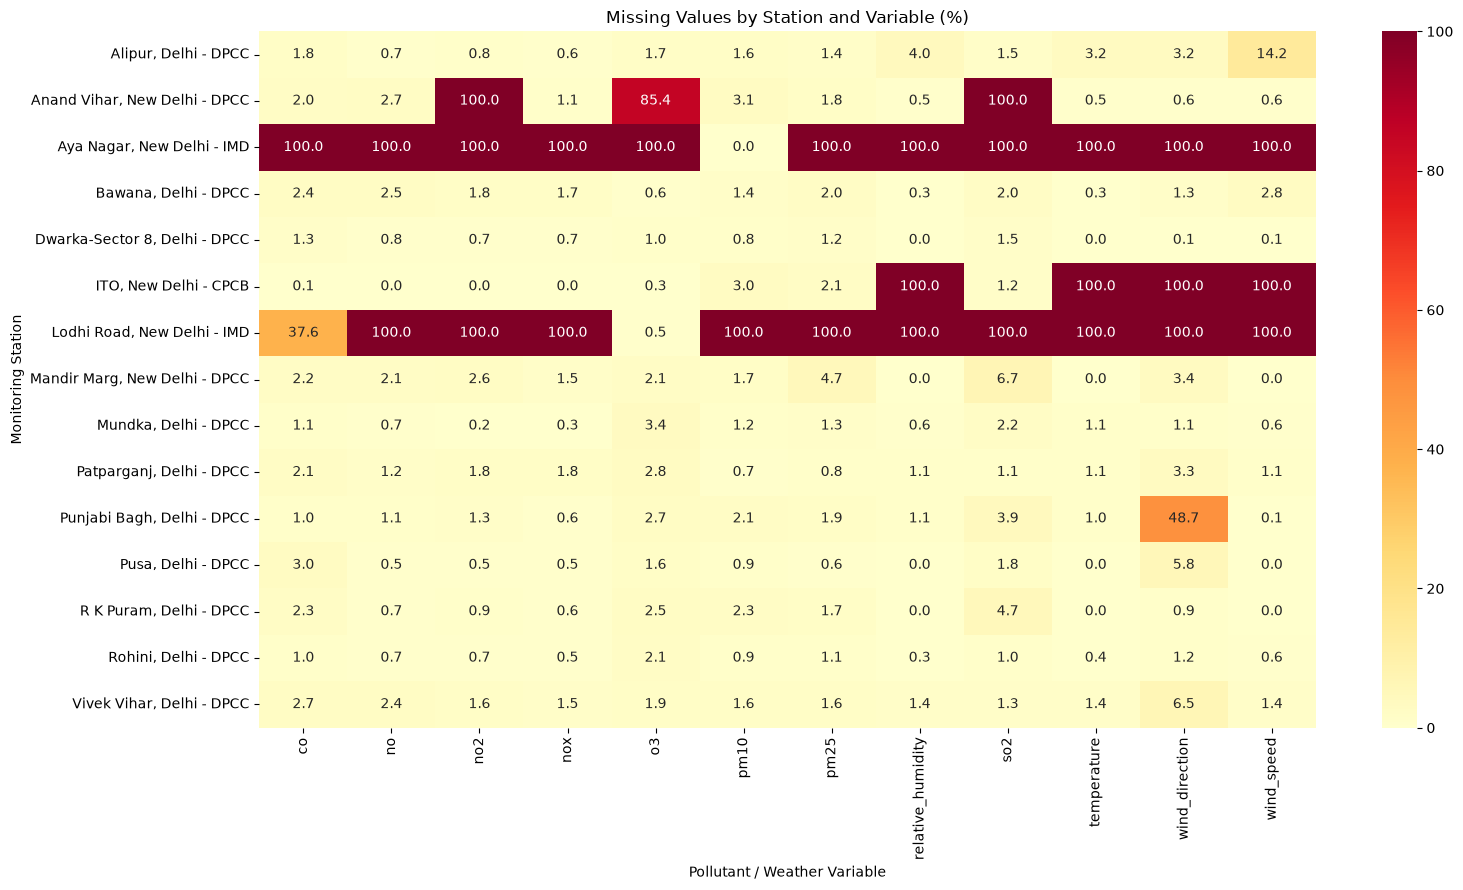

In [19]:
plt.figure(figsize=(16, 9))

sns.heatmap(
    station_variable_missing,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100
)

plt.title("Missing Values by Station and Variable (%)")
plt.xlabel("Pollutant / Weather Variable")
plt.ylabel("Monitoring Station")
plt.tight_layout()
plt.show()

## Raw Data Inspection — Findings and Decisions

### Dataset overview
- 190,514 observations
- 15 monitoring stations
- 19 original columns
- Hourly observations
- Timestamps successfully converted to IST

### Data quality findings
- No exact duplicate rows
- No duplicate station-timestamp pairs
- No invalid timestamps
- Several hourly collection gaps
- Missingness varies considerably by station and variable
- Pollutant distributions are right-skewed
- Extreme readings require investigation, not automatic removal

### Station eligibility
- 13 stations have PM2.5 observations.
- Aya Nagar and Lodhi Road have 100% missing PM2.5.
- These two stations will be excluded from PM2.5-based supervised modelling.

### Initial cleaning policy
- Preserve the original raw dataset.
- Do not invent missing PM2.5 target values.
- Investigate extreme readings before deciding whether to retain them.
- Choose imputation methods according to variable, station and forecasting constraints.
- Avoid using unavailable variables as model predictors.

In [21]:
# Identify stations eligible for PM2.5-based modelling

station_eligibility = (
    clean_df.groupby("station_name")
    .agg(
        Total_Readings=("pm25", "size"),
        Available_PM25=("pm25", "count"),
        Missing_PM25=("pm25", lambda x: x.isna().sum()),
        PM25_Missing_Percentage=(
            "pm25",
            lambda x: x.isna().mean() * 100
        )
    )
    .reset_index()
)

station_eligibility["Eligible"] = (
    station_eligibility["Available_PM25"] > 0
)

display(station_eligibility.sort_values(
    "PM25_Missing_Percentage"
))

print(
    "Eligible stations:",
    station_eligibility["Eligible"].sum()
)

print(
    "Excluded stations:",
    (~station_eligibility["Eligible"]).sum()
)

,station_name,Total_Readings,Available_PM25,Missing_PM25,PM25_Missing_Percentage,Eligible
11,"Pusa, Delhi - DPCC",13888,13801,87,0.626440,True
9,"Patparganj, Delhi - DPCC",13784,13670,114,0.827046,True
13,"Rohini, Delhi - DPCC",14057,13910,147,1.045742,True
4,"Dwarka-Sector 8, Delhi - DPCC",13919,13750,169,1.214168,True
8,"Mundka, Delhi - DPCC",13919,13744,175,1.257274,True
0,"Alipur, Delhi - DPCC",13506,13323,183,1.354953,True
14,"Vivek Vihar, Delhi - DPCC",13769,13549,220,1.597792,True
12,"R K Puram, Delhi - DPCC",13727,13489,238,1.733809,True
1,"Anand Vihar, New Delhi - DPCC",13736,13493,243,1.769074,True
10,"Punjabi Bagh, Delhi - DPCC",13651,13386,265,1.941250,True


Eligible stations: 13
Excluded stations: 2
